# Bean Leaf Disease Classification

## Project Overview

This project uses deep learning to classify bean leaf images into three categories:

- **Angular Leaf Spot**
- **Bean Rust**
- **Healthy**

The dataset is loaded from Hugging Face, and a Convolutional Neural Network (CNN) is used for image classification.

### Objective

To build and evaluate a deep learning model that can identify bean leaf diseases from images.

## 1. Import Libraries

In this section, we import the libraries required to load the dataset, preprocess images, and build the deep learning model.

In [67]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from datasets import load_dataset

## 2. Load Dataset

In this section, we load the Beans dataset from Hugging Face and separate it into training, validation, and test sets.

In [2]:
beans = load_dataset("AI-Lab-Makerere/beans")

train = beans["train"]
validation = beans["validation"]
test = beans["test"]

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.7MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

In [3]:
print(beans)

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})


## 3. Exploratory Data Analysis (EDA)

In this section, we inspect the dataset structure, the number of samples in each split, and the available labels.

In [4]:
# Display the number of samples in each split
print("Training samples:", len(train))
print("Validation samples:", len(validation))
print("Test samples:", len(test))

# Display the available classes
print(train.features["labels"].names)

Training samples: 1034
Validation samples: 133
Test samples: 128
['angular_leaf_spot', 'bean_rust', 'healthy']


## 4. Inspect a Sample

In this section, we inspect a sample image, its dimensions, and its corresponding class label.

In [5]:
# Select one sample from the training set
sample = train[0]

# Display the sample's keys
print(sample.keys())

# Display the image size and label
print("Image size:", sample["image"].size)
print("Label:", sample["labels"])

dict_keys(['image_file_path', 'image', 'labels'])
Image size: (500, 500)
Label: 0


## 5. Visualize a Sample Image

In this section, we visualize a bean leaf image and display its corresponding class label.

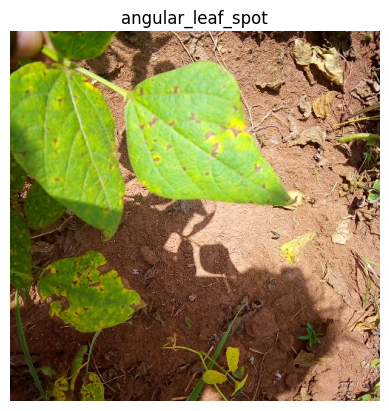

In [6]:
import matplotlib.pyplot as plt

# Select one sample from the training set
sample = train[0]

# Display the image
plt.imshow(sample["image"])
plt.title(train.features["labels"].names[sample["labels"]])
plt.axis("off")
plt.show()

## 6. Image Preprocessing

In this section, we resize the images to a fixed size and normalize pixel values to the range [0, 1]. This makes the images suitable for training the neural network.

In [71]:
def preprocess_images(images):
    images = tf.image.resize(images, (128, 128))
    images = images / 255.0
    return images

### 6.1 Prepare Images and Labels

We preprocess the images and extract their corresponding labels for training, validation, and testing.

In [72]:
# Preprocess images
x_train = preprocess_images(np.array(train["image"]))
x_val = preprocess_images(np.array(validation["image"]))
x_test = preprocess_images(np.array(test["image"]))

# Extract labels
y_train = np.array(train["labels"])
y_val = np.array(validation["labels"])
y_test = np.array(test["labels"])

### 6.2 Verify Data Shapes

We check the shapes of the processed images and labels to ensure they are compatible with the model.

In [73]:
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Validation images:", x_val.shape)
print("Validation labels:", y_val.shape)

print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

Training images: (1034, 128, 128, 3)
Training labels: (1034,)
Validation images: (133, 128, 128, 3)
Validation labels: (133,)
Test images: (128, 128, 128, 3)
Test labels: (128,)


## 7. Build the CNN Model

We build a Convolutional Neural Network (CNN) to classify bean leaf images into three classes. CNNs are well suited for image classification because they can learn spatial features such as edges, textures, and patterns.

In [64]:
###################################
model = keras.Sequential([
    # Input image: 128x128 pixels with 3 RGB channels
    keras.layers.Input(shape=(128, 128, 3)),

    keras.layers.RandomFlip("horizontal"),
    # First convolutional layer: extract basic features
    keras.layers.Conv2D( filters=32, kernel_size=(3, 3), activation="relu"),

    # Reduce the spatial dimensions
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Second convolutional layer: extract more complex features
    keras.layers.Conv2D(filters=64, kernel_size=(3, 3), activation="relu"),

    # Reduce the spatial dimensions again
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Convert feature maps into a one-dimensional vector
    keras.layers.GlobalAveragePooling2D(),

    # Learn patterns from the extracted features
    keras.layers.Dense(128, activation="relu"),

    # Predict one of the three classes
    keras.layers.Dense(3, activation="softmax")
])

In [74]:
model = keras.Sequential([
    keras.layers.Input(shape=(128, 128, 3)),

    keras.layers.RandomFlip("horizontal"),

    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(128, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.GlobalAveragePooling2D(),

    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(3, activation="softmax")
])

## 8. Compile the Model

In this section, we configure the optimizer, loss function, and evaluation metric before training the CNN.

In [75]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## 9. Train the Model

We train the CNN using the training images and labels. The validation set is used to monitor the model's performance during training.

In [76]:
history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_data=(x_val, y_val)
)

Epoch 1/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 21s 618ms/step - accuracy: 0.3781 - loss: 1.0857 - val_accuracy: 0.5338 - val_loss: 1.0581
Epoch 2/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 21s 633ms/step - accuracy: 0.5319 - loss: 1.0270 - val_accuracy: 0.5038 - val_loss: 0.9599
Epoch 3/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 20s 621ms/step - accuracy: 0.5899 - loss: 0.9184 - val_accuracy: 0.6391 - val_loss: 0.8452
Epoch 4/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 20s 601ms/step - accuracy: 0.6074 - loss: 0.8789 - val_accuracy: 0.6090 - val_loss: 0.8276
Epoch 5/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 22s 638ms/step - accuracy: 0.6035 - loss: 0.8799 - val_accuracy: 0.6165 - val_loss: 0.8169
Epoch 6/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 21s 622ms/step - accuracy: 0.6344 - loss: 0.8430 - val_accuracy: 0.6617 - val_loss: 0.7942
Epoch 7/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 40s 598ms/step - accuracy: 0.6277 - loss: 0.8250 - val_accuracy: 0.6617 - val_loss: 0.7858
Epoch 8/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 21s 602ms/step - accuracy: 0.6412 - loss: 0.8102 - val_accu

## 10. Evaluate the Model

We evaluate the trained CNN on the test set to measure its performance on unseen images.

In [77]:
test_loss, test_accuracy = model.evaluate( x_test,y_test, verbose=1)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 175ms/step - accuracy: 0.6406 - loss: 0.7010
Test Loss: 0.7010021209716797
Test Accuracy: 0.640625


## 11. Visualize Training Performance

We plot the training and validation accuracy to observe the model's learning progress and compare its performance on both datasets.

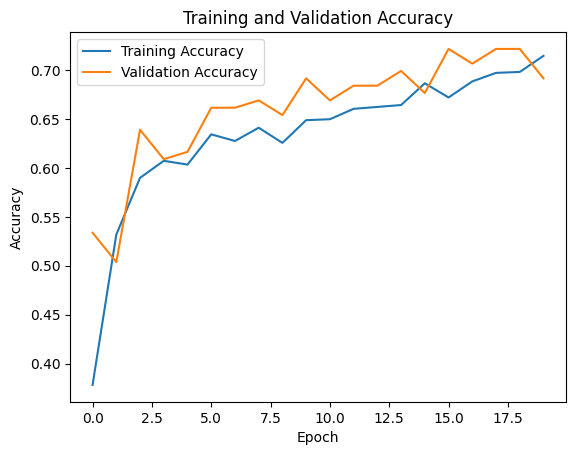

In [78]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

In [79]:
for epoch, (train_acc, val_acc) in enumerate(
    zip(history.history["accuracy"], history.history["val_accuracy"]),
    start=1
):
    print(
        f"Epoch {epoch:02d} | "
        f"Train Accuracy: {train_acc:.3f} | "
        f"Validation Accuracy: {val_acc:.3f}"
    )

Epoch 01 | Train Accuracy: 0.378 | Validation Accuracy: 0.534
Epoch 02 | Train Accuracy: 0.532 | Validation Accuracy: 0.504
Epoch 03 | Train Accuracy: 0.590 | Validation Accuracy: 0.639
Epoch 04 | Train Accuracy: 0.607 | Validation Accuracy: 0.609
Epoch 05 | Train Accuracy: 0.603 | Validation Accuracy: 0.617
Epoch 06 | Train Accuracy: 0.634 | Validation Accuracy: 0.662
Epoch 07 | Train Accuracy: 0.628 | Validation Accuracy: 0.662
Epoch 08 | Train Accuracy: 0.641 | Validation Accuracy: 0.669
Epoch 09 | Train Accuracy: 0.626 | Validation Accuracy: 0.654
Epoch 10 | Train Accuracy: 0.649 | Validation Accuracy: 0.692
Epoch 11 | Train Accuracy: 0.650 | Validation Accuracy: 0.669
Epoch 12 | Train Accuracy: 0.661 | Validation Accuracy: 0.684
Epoch 13 | Train Accuracy: 0.662 | Validation Accuracy: 0.684
Epoch 14 | Train Accuracy: 0.664 | Validation Accuracy: 0.699
Epoch 15 | Train Accuracy: 0.687 | Validation Accuracy: 0.677
Epoch 16 | Train Accuracy: 0.672 | Validation Accuracy: 0.722
Epoch 17

In [80]:
from sklearn.metrics import classification_report
import numpy as np

y_pred = np.argmax(model.predict(x_test), axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=[
        "angular_leaf_spot",
        "bean_rust",
        "healthy"
    ]
))

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 171ms/step
                   precision    recall  f1-score   support

angular_leaf_spot       0.74      0.72      0.73        43
        bean_rust       0.56      0.33      0.41        43
          healthy       0.61      0.88      0.72        42

         accuracy                           0.64       128
        macro avg       0.63      0.64      0.62       128
     weighted avg       0.64      0.64      0.62       128



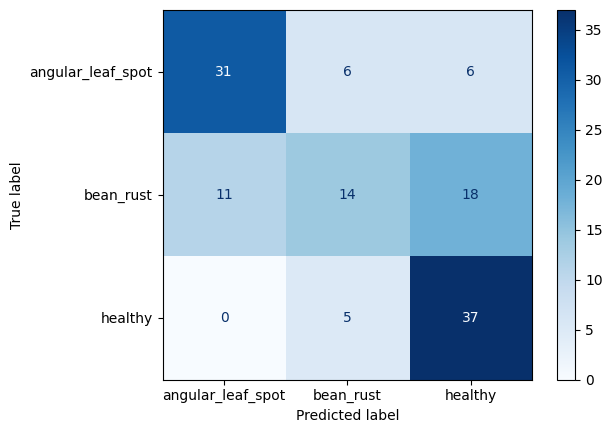

[[31  6  6]
 [11 14 18]
 [ 0  5 37]]


In [81]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "angular_leaf_spot",
        "bean_rust",
        "healthy"
    ]
)

display.plot(cmap="Blues", values_format="d")
plt.show()
print(confusion_matrix(y_test, y_pred))